# FALCON H1 — Working with the neuralset `Study` (`FanFalconH1`)

This notebook shows how the per-dataset `Study` in `study.py` turns the source data into the **canonical events DataFrame** the neuroai pipeline consumes.

We walk through:
1. instantiating the `Study` and pointing it at the data,
2. **timelines** — the unit of work (`iter_timelines`),
3. the per-timeline events (`_load_timeline_events`): one `Spikes`, three continuous-kinematics series, and one event per **task phase** (`Stimulus` / `Action` / `Intertrial`),
4. the standardized output (`run()`) and what `standardize_events` adds,
5. binning the `Spikes` event into a feature array with `SpikesExtractor`,
6. the 7-DoF kinematics split into `PositionSeries` / `OrientationSeries` / `GraspSeries`, read into `(n_dims, T)` windows with `BehavioralSeriesExtractor`.

## 1. Instantiate the Study

`Study(path=...)` auto-resolves its own data subfolder and records caching infra.

`download()` would pull dandiset 000954 from DANDI; we skip it since the data is
already local — the events read the local `.nwb` files in place.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import pandas as pd

from neuralshed.datasets.fan_h1 import study
from neuralshed.datasets.utils import dataset_dir
from neuralset.events.study import STUDIES

# Importing the study module above registers FanFalconH1 by class name
print("FanFalconH1 registered:", "FanFalconH1" in STUDIES)

# Instantiate Study
s = study.FanFalconH1(path=dataset_dir("fan_h1") / "data")

print("study    :", s.__class__.__name__)
print("self.path:", s.path)          # auto-resolved to the folder holding sub-HumanPitt-*
print("aliases  :", s.aliases)
print("licence  :", s.licence)
print("requires :", s.requirements)

FanFalconH1 registered: True
study    : FanFalconH1
self.path: /Volumes/seagate_0/tether/datasets/fan_h1/data/FanFalconH1
aliases  : ('FALCON Benchmark H1', 'FALCON-H1')
licence  : CC-BY-4.0
requires : ('dandi', 'pynwb', 'h5py')


You can use the `.download()` method to fetch dandiset files locally. If no local files exist, the Study will stream whenever needed.

In [2]:
s.download()

2026-06-26 16:23:46 - INFO - neuralset.events.study:396 - Success: Study downloaded to /Volumes/seagate_0/tether/datasets/fan_h1/data/FanFalconH1.
2026-06-26 16:23:50 - INFO - neuralset.events.study:86 - Permissions set for /Volumes/seagate_0/tether/datasets/fan_h1/data/FanFalconH1 (skipped 0 non-owned items).


## 2. Timelines — the unit of work

A **timeline** is the smallest independently-loadable recording unit; here that is
one released NWB session. `iter_timelines()` yields plain dicts. The `subject` key
is mandatory; extra keys (`session`, `original_split`, `task`) become event columns. The
`path` key is special — the base class resolves it to a file and never turns it
into a column. We store a **relative** path so the timeline id (used as the cache
key) stays portable across machines/drives.

In [3]:
timelines = list(s.iter_timelines())
tldf = pd.DataFrame(timelines)

print("n timelines:", len(timelines))            # 40 released sessions
display(tldf.groupby("original_split").size().rename("n_timelines").to_frame())

n timelines: 40


,n_timelines
original_split,
held-in-calib,13
held-in-minival,13
held-out-calib,14


In [4]:
display(tldf.head(6))

,subject,session,original_split,task,path
0,HumanPitt,sub-HumanPitt-held-in-calib_ses-19250101T111740,held-in-calib,reach_grasp,000954/sub-HumanPitt-held-in-calib/sub-HumanPi...
1,HumanPitt,sub-HumanPitt-held-in-calib_ses-19250101T112404,held-in-calib,reach_grasp,000954/sub-HumanPitt-held-in-calib/sub-HumanPi...
2,HumanPitt,sub-HumanPitt-held-in-calib_ses-19250108T110520,held-in-calib,reach_grasp,000954/sub-HumanPitt-held-in-calib/sub-HumanPi...
3,HumanPitt,sub-HumanPitt-held-in-calib_ses-19250108T111022,held-in-calib,reach_grasp,000954/sub-HumanPitt-held-in-calib/sub-HumanPi...
4,HumanPitt,sub-HumanPitt-held-in-calib_ses-19250108T111455,held-in-calib,reach_grasp,000954/sub-HumanPitt-held-in-calib/sub-HumanPi...
5,HumanPitt,sub-HumanPitt-held-in-calib_ses-19250113T120811,held-in-calib,reach_grasp,000954/sub-HumanPitt-held-in-calib/sub-HumanPi...


## 3. Events for one timeline (`_load_timeline_events`)

For each timeline the Study emits **one `Spikes` event**, **three continuous-kinematics events**, plus **one event per `intervals/epochs` row** — and each epochs row is a single *task phase* (not a whole trial), carrying exactly one tag. The phases tile each trial in the canonical reach-grasp-transport sequence and are split three ways by tag (see the dataset README → *Task phases & events*):

* **`Spikes`** — the whole-session multi-unit `Units` table, pointing at the local `.nwb` (`filepath`), `frequency=50 Hz`, `duration` = recording span; the spike→array binning happens later, in `SpikesExtractor` (§5).
* **`PositionSeries` / `OrientationSeries` / `GraspSeries`** — the whole-session 7-DoF kinematics, **split into three homogeneous streams** (`dims=(x,y,z)` / `(x,)` / `(g1,g2,g3)`) at 50 Hz, loaded on demand from the NWB via a `SpecialLoader` and read by `BehavioralSeriesExtractor` (§6). The raw 7-DoF mixes translation + rotation + grasp, so one mixed vector would be dishonest.
* **`Stimulus`** — the `Presentation*` *cue* phases (the limb is held still while the next target is shown). The number is positional, so each cue's `code` is set to the `code` of the `Action` it precedes, with `description="cue: <Action>"`.
* **`Action`** — the attempted-movement phases (`Reach`, `Orient`, `SnapTo`, `Shape`, `Grasp`, `Carry`, `Orient2`, `Release`), one `code` each. `Orient` (pre-grasp) and `Orient2` (the references' *Reorient* phase) are distinct movements. These are observation data, so `task_condition="attempted"`.
* **`Intertrial`** — the rest gap between trials (a custom marker event).

This is the *raw* per-timeline output, before standardization — no `subject` column yet (the base class injects it next).

In [5]:
tl0 = timelines[0]
print("timeline:", tl0["session"], "|", tl0["original_split"])
raw = s._load_timeline_events(tl0)
print("shape:", raw.shape)
print("event types:", raw["type"].value_counts().to_dict())

# the per-phase events (everything but the whole-session Spikes + kinematics), in
# time order: note the interleaved cue (Stimulus) -> movement (Action) structure.
cols = ["type", "start", "duration", "code", "description", "task_condition", "cue_tag"]
whole_session = ["Spikes", "PositionSeries", "OrientationSeries", "GraspSeries"]
phases = raw[~raw["type"].isin(whole_session)]
display(phases[[c for c in cols if c in phases.columns]].head(12))

timeline: sub-HumanPitt-held-in-calib_ses-19250101T111740 | held-in-calib
shape: (194, 12)
event types: {'Action': 103, 'Stimulus': 83, 'Spikes': 1, 'PositionSeries': 1, 'OrientationSeries': 1, 'GraspSeries': 1, 'LinearVelocitySeries': 1, 'AngularVelocitySeries': 1, 'GraspVelocitySeries': 1, 'Intertrial': 1}


,type,start,duration,code,description,task_condition,cue_tag
4,LinearVelocitySeries,0.00,216.38,NaN,NaN,NaN,NaN
5,AngularVelocitySeries,0.00,216.38,NaN,NaN,NaN,NaN
6,GraspVelocitySeries,0.00,216.38,NaN,NaN,NaN,NaN
7,Action,0.00,0.06,7.0,Release,attempted,NaN
8,Stimulus,0.06,1.02,0.0,cue: Reach,NaN,Presentation
9,Action,1.08,0.04,0.0,Reach,attempted,NaN
10,Action,1.12,0.02,1.0,Orient,attempted,NaN
11,Action,1.14,0.50,2.0,SnapTo,attempted,NaN
12,Stimulus,1.64,1.52,3.0,cue: Shape,NaN,Presentation3
13,Action,3.16,0.62,3.0,Shape,attempted,NaN


Each `Presentation*` cue shares the `code` of the `Action` it precedes, so a cue and its target movement carry the same class label. The mapping is defined in `study.py` (`_CUE_TO_ACTION`, `_ACTION_CODES`):

In [6]:
from neuralshed.datasets.fan_h1.study import _ACTION_CODES, _CUE_TO_ACTION

corr = pd.DataFrame(
    [(cue, action, _ACTION_CODES[action]) for cue, action in _CUE_TO_ACTION.items()],
    columns=["Stimulus (cue)", "cues Action", "shared code"],
)
display(corr)
# SnapTo (code 2) follows Orient directly with no cue, so code 2 never appears on a Stimulus:
print("Action codes      :", _ACTION_CODES)
print("codes used by cues:", sorted({_ACTION_CODES[a] for a in _CUE_TO_ACTION.values()}))

,Stimulus (cue),cues Action,shared code
0,Presentation,Reach,0
1,Presentation2,Orient,1
2,Presentation3,Shape,3
3,Presentation4,Grasp,4
4,Presentation5,Carry,5
5,Presentation6,Orient2,6
6,Presentation7,Release,7


Action codes      : {'Reach': 0, 'Orient': 1, 'SnapTo': 2, 'Shape': 3, 'Grasp': 4, 'Carry': 5, 'Orient2': 6, 'Release': 7}
codes used by cues: [0, 1, 3, 4, 5, 6, 7]


## 4. The canonical output (`run()`)

`run()` loads every timeline and **standardizes** the events: it namespaces
`subject` (`FanFalconH1/HumanPitt`), builds the `timeline` id, sets `study`,
computes `stop = start + duration`, and fills BIDS entities (`session`, `task`,
`run`). Per-timeline loading is cached (exca), so re-runs are fast.

The full run covers all 40 timelines.

In [7]:
pd.set_option('display.max_columns', None)

demo = study.FanFalconH1(
    path=dataset_dir("fan_h1") / "data",
    query="timeline_index == 8",
)
events = demo.run()
print("events:", events.shape)

added = [c for c in events.columns if c not in raw.columns]
print("added by standardize_events:", added)

display(events.head(8))
print("subject :", events["subject"].iloc[0])
print("timeline:", events["timeline"].iloc[0])

events: (222, 23)
added by standardize_events: ['timeline', 'subject', 'session', 'task', 'run', 'study', 'original_split', 'feature', 'kind', 'modality', 'stop']


,type,start,duration,timeline,subject,session,task,run,frequency,filepath,dims,unit,reference_frame,description,code,cue_tag,task_condition,study,original_split,feature,kind,modality,stop
0,Spikes,0.0,245.34,"FanFalconH1:original_split=held-in-calib,path=...",FanFalconH1/HumanPitt,sub-HumanPitt-held-in-calib_ses-19250115T111328,reach_grasp,,50.0,"{""cls"":""FanFalconH1"",""method"":""_load_spikes"",""...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,FanFalconH1,held-in-calib,NaN,NaN,NaN,245.34
1,PositionSeries,0.0,245.34,"FanFalconH1:original_split=held-in-calib,path=...",FanFalconH1/HumanPitt,sub-HumanPitt-held-in-calib_ses-19250115T111328,reach_grasp,,50.0,"{""cls"":""FanFalconH1"",""kwargs"":{""cols"":[0,1,2],...","(x, y, z)",arbitrary,open-loop target kinematics (Pittsburgh reach-...,NaN,NaN,NaN,NaN,FanFalconH1,held-in-calib,,,NaN,245.34
2,OrientationSeries,0.0,245.34,"FanFalconH1:original_split=held-in-calib,path=...",FanFalconH1/HumanPitt,sub-HumanPitt-held-in-calib_ses-19250115T111328,reach_grasp,,50.0,"{""cls"":""FanFalconH1"",""kwargs"":{""cols"":[3],""key...","(x,)",arbitrary,open-loop target kinematics (Pittsburgh reach-...,NaN,NaN,NaN,NaN,FanFalconH1,held-in-calib,,,NaN,245.34
3,GraspSeries,0.0,245.34,"FanFalconH1:original_split=held-in-calib,path=...",FanFalconH1/HumanPitt,sub-HumanPitt-held-in-calib_ses-19250115T111328,reach_grasp,,50.0,"{""cls"":""FanFalconH1"",""kwargs"":{""cols"":[4,5,6],...","(g1, g2, g3)",arbitrary,open-loop target kinematics (Pittsburgh reach-...,NaN,NaN,NaN,NaN,FanFalconH1,held-in-calib,,,NaN,245.34
4,LinearVelocitySeries,0.0,245.34,"FanFalconH1:original_split=held-in-calib,path=...",FanFalconH1/HumanPitt,sub-HumanPitt-held-in-calib_ses-19250115T111328,reach_grasp,,50.0,"{""cls"":""FanFalconH1"",""kwargs"":{""cols"":[0,1,2],...","(x, y, z)",arbitrary,open-loop target kinematics (Pittsburgh reach-...,NaN,NaN,NaN,NaN,FanFalconH1,held-in-calib,,,NaN,245.34
5,AngularVelocitySeries,0.0,245.34,"FanFalconH1:original_split=held-in-calib,path=...",FanFalconH1/HumanPitt,sub-HumanPitt-held-in-calib_ses-19250115T111328,reach_grasp,,50.0,"{""cls"":""FanFalconH1"",""kwargs"":{""cols"":[3],""key...","(x,)",arbitrary,open-loop target kinematics (Pittsburgh reach-...,NaN,NaN,NaN,NaN,FanFalconH1,held-in-calib,,,NaN,245.34
6,GraspVelocitySeries,0.0,245.34,"FanFalconH1:original_split=held-in-calib,path=...",FanFalconH1/HumanPitt,sub-HumanPitt-held-in-calib_ses-19250115T111328,reach_grasp,,50.0,"{""cls"":""FanFalconH1"",""kwargs"":{""cols"":[4,5,6],...","(g1, g2, g3)",arbitrary,open-loop target kinematics (Pittsburgh reach-...,NaN,NaN,NaN,NaN,FanFalconH1,held-in-calib,,,NaN,245.34
7,Intertrial,0.0,0.08,"FanFalconH1:original_split=held-in-calib,path=...",FanFalconH1/HumanPitt,sub-HumanPitt-held-in-calib_ses-19250115T111328,reach_grasp,,NaN,NaN,NaN,NaN,NaN,Intertrial,NaN,NaN,NaN,FanFalconH1,held-in-calib,NaN,NaN,NaN,0.08


subject : FanFalconH1/HumanPitt
timeline: FanFalconH1:original_split=held-in-calib,path=000954/sub-HumanPitt-held-in-calib/sub-HumanPitt-held-in-calib_ses-19250115T111328.nwb,session=sub-HumanPitt-held-in-calib_ses-19250115T111328,subject=HumanPitt,task=reach_grasp


## 5. From a `Spikes` event to a feature array (`SpikesExtractor`)

The `Spikes` event only *points* at the NWB. The binning into a dense
`(n_units, n_bins)` array happens in `SpikesExtractor`, which reads
`units/spike_times` from the file and bins at the event's frequency (50 Hz). This
is the same neural data the source notebook binned with `utils.bin_spikes`, but
via the production extractor: it bins to the spike extent and then crops to
`[start, start + duration]`.

In [8]:
from neuralset.events import etypes
from neuralset.extractors import SpikesExtractor

spikes_event = etypes.Event.from_dict(events[events.type == "Spikes"].iloc[0].to_dict())
print("Spikes event: dur =", spikes_event.duration, "s @", spikes_event.frequency, "Hz")

ex = SpikesExtractor()                       # frequency="native" -> event.frequency (50 Hz)

first5s = ex(events=spikes_event, start=0.0, duration=5.0)
print("binned first 5 s:", tuple(first5s.shape), "(n_units, 5*50 bins)")

full    = ex(events=spikes_event, start=spikes_event.start, duration=spikes_event.duration)
print("binned full     :", tuple(full.shape), "(n_units, dur*50 bins)")

Spikes event: dur = 245.34 s @ 50.0 Hz
binned first 5 s: (176, 250) (n_units, 5*50 bins)
binned full     : (176, 12267) (n_units, dur*50 bins)


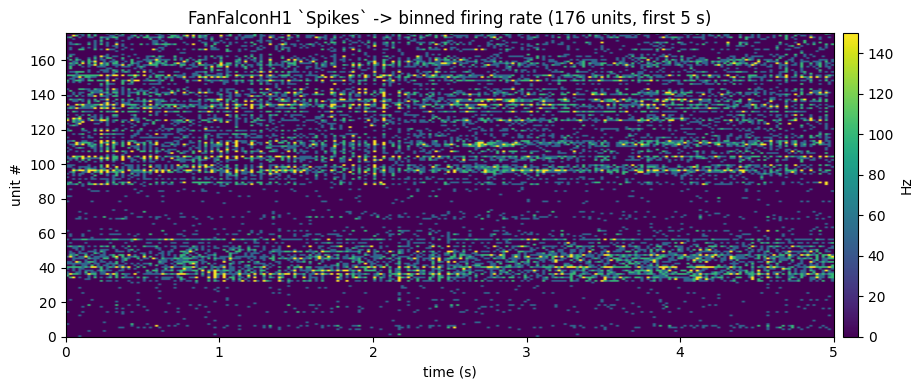

In [9]:
import numpy as np
import matplotlib.pyplot as plt

counts = first5s.numpy()
rate = counts / (1.0 / spikes_event.frequency)   # spikes/bin -> Hz
fig, ax = plt.subplots(figsize=(10, 4))
im = ax.imshow(rate, aspect="auto", origin="lower", cmap="viridis",
               vmax=np.percentile(rate, 99), extent=[0, 5, 0, rate.shape[0]])
ax.set(xlabel="time (s)", ylabel="unit #",
       title=f"FanFalconH1 `Spikes` -> binned firing rate "
             f"({rate.shape[0]} units, first 5 s)")
fig.colorbar(im, ax=ax, label="Hz", pad=0.01)
plt.tight_layout()
plt.show()

## 6. Continuous kinematics → `PositionSeries` / `OrientationSeries` / `GraspSeries`

The 7-DoF `OpenLoopKinematics` mixes three physically different quantities (3 translation, 1 wrist rotation, 3 grasp — all normalized), so it is emitted as **three homogeneous** custom neuralshed events rather than one mixed vector:
`PositionSeries` (`dims=(x,y,z)` from `tx,ty,tz`), `OrientationSeries` (`dims=(x,)` from the wrist-rotation `rx`), and `GraspSeries` (`dims=(g1,g2,g3)`). All subclass `BehavioralSeries`.

Like `Spikes`, each event only *points* at the data — here through a `SpecialLoader` that lazily reads its columns from the NWB. `BehavioralSeriesExtractor` windows each to `(n_dims, T)` at the **same** 50 Hz as the binned spikes, so a sequence-to-sequence model can regress the trajectory within a segment `(B, n_units, T) → (B, n_dims, T)`. Selection is **by type**, so wire one stream per extractor (`event_types="PositionSeries"`); the `kind` field is for queries/provenance, not selection.

In [10]:
from neuralshed.extractors import BehavioralSeriesExtractor

kin = events[events.type.isin(["PositionSeries", "OrientationSeries", "GraspSeries"])]
display(kin[["type", "start", "duration", "frequency", "dims", "unit"]])

# Each homogeneous stream is selected BY TYPE and windowed to (n_dims, T).
for etype in ["PositionSeries", "OrientationSeries", "GraspSeries"]:
    ev = etypes.Event.from_dict(events[events.type == etype].iloc[0].to_dict())
    win = BehavioralSeriesExtractor(event_types=etype, frequency=50.0)(ev, start=0.0, duration=5.0)
    print(f"{etype:18} dims={ev.dims}  first 5 s -> {tuple(win.shape)}  (n_dims, 5*50)")

# keep the position window for the plot below (same 50 Hz grid as the binned spikes)
pos_event = etypes.Event.from_dict(events[events.type == "PositionSeries"].iloc[0].to_dict())
pos5s = BehavioralSeriesExtractor(event_types="PositionSeries", frequency=50.0)(
    pos_event, start=0.0, duration=5.0)

,type,start,duration,frequency,dims,unit
1,PositionSeries,0.0,245.34,50.0,"(x, y, z)",arbitrary
2,OrientationSeries,0.0,245.34,50.0,"(x,)",arbitrary
3,GraspSeries,0.0,245.34,50.0,"(g1, g2, g3)",arbitrary


PositionSeries     dims=('x', 'y', 'z')  first 5 s -> (3, 250)  (n_dims, 5*50)
OrientationSeries  dims=('x',)  first 5 s -> (1, 250)  (n_dims, 5*50)
GraspSeries        dims=('g1', 'g2', 'g3')  first 5 s -> (3, 250)  (n_dims, 5*50)


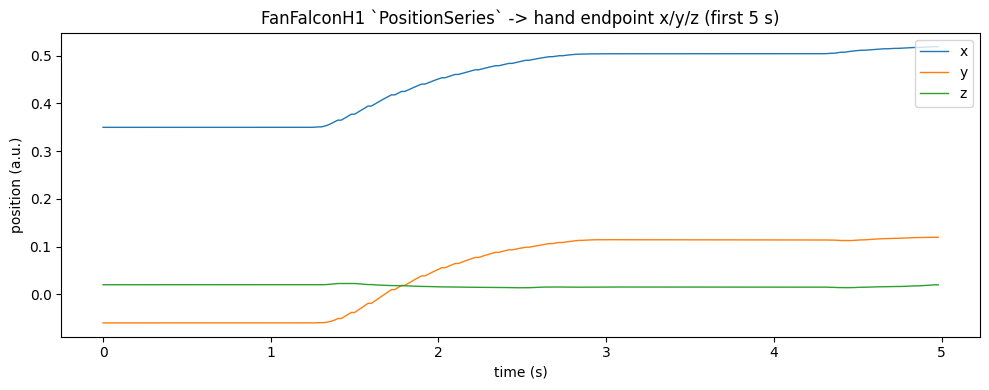

In [11]:
pos = pos5s.numpy()                            # (3, 250)
t = np.arange(pos.shape[1]) / pos_event.frequency
fig, ax = plt.subplots(figsize=(10, 4))
for i, name in enumerate(pos_event.dims):
    ax.plot(t, pos[i], lw=1, label=name)
ax.set(xlabel="time (s)", ylabel="position (a.u.)",
       title="FanFalconH1 `PositionSeries` -> hand endpoint x/y/z (first 5 s)")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()